<a href="https://colab.research.google.com/github/Avinash2567/Avinash2567/blob/main/SVM/linear_svm_sonar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
print("Uploaded file:", filename)

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename, header=None)
elif filename.lower().endswith((".csv", ".txt")):
    df = pd.read_csv(filename, header=None)
else:
    # Try CSV first, then Excel if necessary
    try:
        df = pd.read_csv(filename, header=None)
    except Exception:
        df = pd.read_excel(filename, header=None)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving sonar.csv to sonar (1).csv
Uploaded file: sonar (1).csv
Dataset loaded successfully!
Shape: (208, 61)


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [3]:
# Remove completely empty rows and columns
df = df.dropna(how="all").dropna(axis=1, how="all")

# The standard Sonar dataset has 60 features + 1 label.
# Remove rows with missing values for this basic implementation.
df = df.dropna().reset_index(drop=True)

# Separate features and target
X = df.iloc[:, :-1].apply(pd.to_numeric, errors="coerce")
y = df.iloc[:, -1].astype(str).str.strip().str.upper()

# Remove rows that could not be converted to numerical features
valid = X.notna().all(axis=1)
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass distribution:")
print(y.value_counts())

print("\nUnique labels:", y.unique())

Features shape: (208, 60)
Target shape: (208,)

Class distribution:
60
M    111
R     97
Name: count, dtype: int64

Unique labels: ['R' 'M']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 166
Testing samples: 42


In [7]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0, probability=True))
])

linear_svm.fit(X_train, y_train)

linear_pred = linear_svm.predict(X_test)

print("Linear SVM trained successfully!")

Linear SVM trained successfully!


In [8]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True))
])

rbf_svm.fit(X_train, y_train)

rbf_pred = rbf_svm.predict(X_test)

print("RBF SVM trained successfully!")

RBF SVM trained successfully!


In [9]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    # Use M as the positive class (mine)
    positive_class = "M"
    scores = model.predict_proba(X_test)[
        :, list(model.classes_).index(positive_class)
    ]

    return {
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, predictions, pos_label=positive_class) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions, pos_label=positive_class) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(y_test, predictions, pos_label=positive_class) * 100, 2
        ),
        "ROC-AUC": round(roc_auc_score(
            (y_test == positive_class).astype(int), scores
        ), 3)
    }

results = pd.DataFrame([
    evaluate_model("Linear SVM", linear_svm, X_test, y_test),
    evaluate_model("RBF SVM", rbf_svm, X_test, y_test)
])

display(results)

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),ROC-AUC
0,Linear SVM,76.19,73.08,86.36,79.17,0.848
1,RBF SVM,85.71,80.77,95.45,87.50,0.925


In [10]:
print("===== LINEAR SVM =====")
print(classification_report(
    y_test,
    linear_svm.predict(X_test),
    labels=["M", "R"],
    target_names=["Mine", "Rock"],
    zero_division=0
))

print("===== RBF SVM =====")
print(classification_report(
    y_test,
    rbf_svm.predict(X_test),
    labels=["M", "R"],
    target_names=["Mine", "Rock"],
    zero_division=0
))

===== LINEAR SVM =====
              precision    recall  f1-score   support

        Mine       0.73      0.86      0.79        22
        Rock       0.81      0.65      0.72        20

    accuracy                           0.76        42
   macro avg       0.77      0.76      0.76        42
weighted avg       0.77      0.76      0.76        42

===== RBF SVM =====
              precision    recall  f1-score   support

        Mine       0.81      0.95      0.88        22
        Rock       0.94      0.75      0.83        20

    accuracy                           0.86        42
   macro avg       0.87      0.85      0.85        42
weighted avg       0.87      0.86      0.86        42



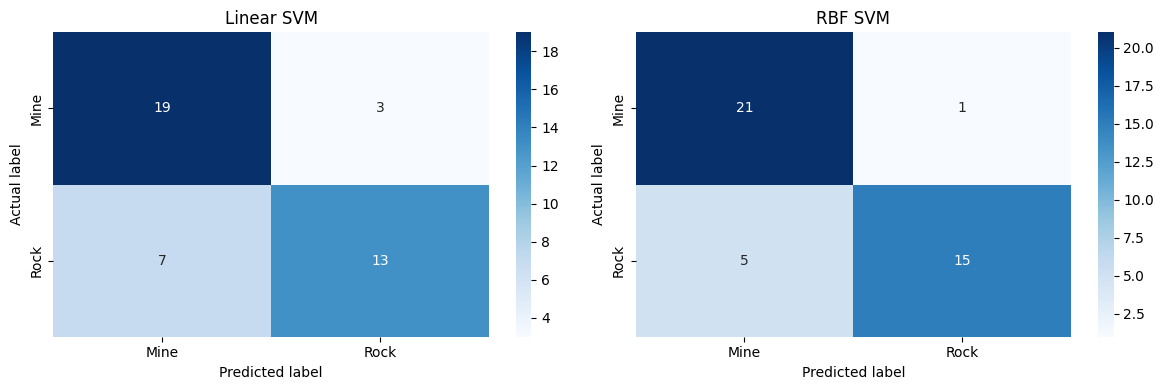

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, model, title in [
    (axes[0], linear_svm, "Linear SVM"),
    (axes[1], rbf_svm, "RBF SVM")
]:
    cm = confusion_matrix(
        y_test, model.predict(X_test), labels=["M", "R"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Mine", "Rock"],
        yticklabels=["Mine", "Rock"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

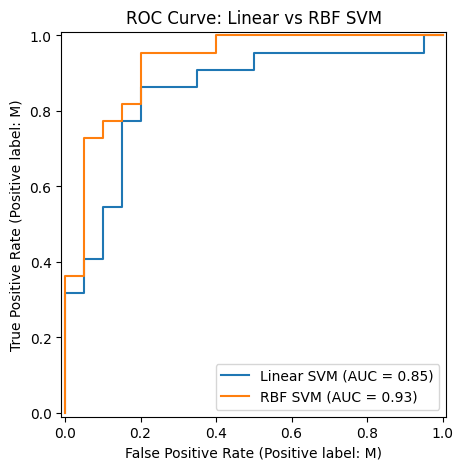

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

for model, name in [
    (linear_svm, "Linear SVM"),
    (rbf_svm, "RBF SVM")
]:
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        pos_label="M",
        ax=ax,
        name=name
    )

ax.set_title("ROC Curve: Linear vs RBF SVM")
plt.show()

Variance retained by 2 components: 40.72 %


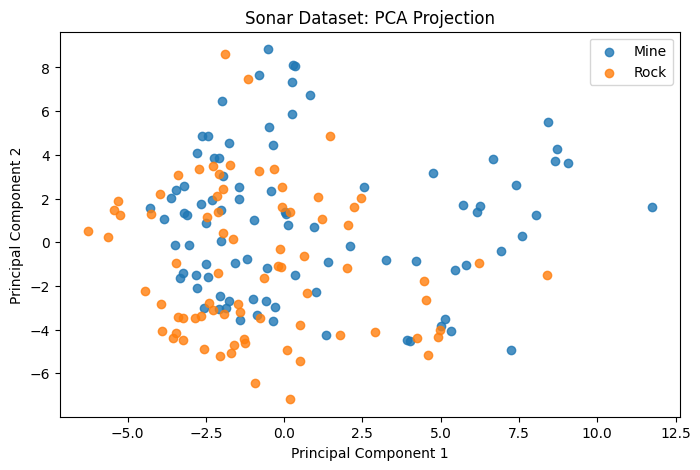

In [14]:
# Fit PCA on scaled training features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)

print(
    "Variance retained by 2 components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plt.figure(figsize=(8, 5))

for label, name in [("M", "Mine"), ("R", "Rock")]:
    mask = y_train.to_numpy() == label
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        label=name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Sonar Dataset: PCA Projection")
plt.legend()
plt.show()

In [15]:
best_model = results.loc[results["F1-score (%)"].idxmax(), "Model"]

print(results.to_string(index=False))
print("\nHigher test F1-score:", best_model)

     Model  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)  ROC-AUC
Linear SVM         76.19          73.08       86.36         79.17    0.848
   RBF SVM         85.71          80.77       95.45         87.50    0.925

Higher test F1-score: RBF SVM
